In [3]:
import matplotlib.pyplot as plt
from astropy.io import fits
import numpy as np
from sunsim import *

from astropy import units as u
from specutils import Spectrum1D
from specutils.manipulation import FluxConservingResampler
import scipy.integrate as integrate




In [4]:
def black_body(wv,T):
    #Computes the BB flux with temperature T at wavelengths wv(in nanometers)
    c = 2.99792458e10 #speed of light in cm/s
    k = 1.380658e-16  #boltzmann constant
    h = 6.6260755e-27 #planck
    w=wv*1e-8 #Angstrom to cm
    bb=2*h*c**2*w**(-5)*(np.exp(h*c/k/T/w)-1)**(-1)
    return bb

def vacuum2air(wv): #wv in angstroms
	wv=wv*1e-4 #A to micrometer
	a=0
	b1=5.792105e-2
	b2=1.67917e-3
	c1=238.0185
	c2=57.362

	n=1+a+b1/(c1-(1/wv**2))+b2/(c2-(1/wv**2))

	w=(wv/n)*1e4 #to Angstroms
	return w

In [5]:
##### Parameters #####

N_rings = 10
ccf_mask = None
instrument = None
rv_ccf = None
inclination = np.deg2rad(7.25)
rotation_period = 24.47
stellar_radius = 1                                        
stellar_mass = 1                                   
logg = 4.4  
differential_rotation = 0     
simulate_planet = False
time = np.linspace(0,25, 25)
spot_dT = 500
T_quiet = 5770

rotation_in_spectra = True

# fluxes
flux_quiet = np.load('/Users/sophiestucki/Downloads/vxdrift_corrected_ssd_spectra/av_solar_ssd_10_mu_angles_angles_PHOENIX_high_res_grid.npy', allow_pickle=True).item()
# flux_quiet = np.load('/Users/sophiestucki/Downloads/vxdrift_corrected_ssd_spectra/av_solar_ssd_10_mu_angles_PHOENIX_low_res_specint_grid.npy', allow_pickle=True).item()


flux_fc = np.load('/Users/sophiestucki/Downloads/vxdrift_corrected_200G_spectra/av_solar_faculae_200G_10_mu_angles_PHOENIX_high_res_grid.npy', allow_pickle=True).item()
flux_sp =  np.load('/Users/sophiestucki/Downloads/vxdrift_corrected_ssd_spectra/av_solar_ssd_10_mu_angles_angles_PHOENIX_high_res_grid.npy', allow_pickle=True).item()

for mu in flux_sp.keys():
    flux_sp[mu]['intensity'] *= black_body(flux_sp[mu]['wav'], (T_quiet-spot_dT)) / black_body(flux_sp[mu]['wav'], T_quiet) 
    


# CCFs >TODO: CCF function ç
ccf_quiet = None
ccf_fc = None
ccf_sp = None

# Grids 
flux_grid_quiet = flux_grid(N_rings, flux_quiet, 'quiet', None, 3800, 8000, rotation_period=rotation_period, inclination=inclination, stellar_radius=stellar_radius)
flux_grid_quiet.rest_frame_grid()

flux_grid_sp = flux_grid(N_rings, flux_sp, 'sp', None, 3800, 8000, rotation_period=rotation_period, inclination=inclination, stellar_radius=stellar_radius)
flux_grid_sp.rest_frame_grid()

flux_grid_fc = flux_grid(N_rings, flux_fc, 'fc', None, 3800, 8000, rotation_period=rotation_period, inclination=inclination, stellar_radius=stellar_radius)
flux_grid_fc.rest_frame_grid()


In [4]:
flux_grid_quiet.rotating_grid()
flux_grid_fc.rotating_grid()
flux_grid_sp.rotating_grid()



In [5]:
# [plt.plot(flux_grid_quiet.wv_grid, flux_grid_quiet.grid[k]) for k in range(np.sum(flux_grid_quiet.Ngrid_in_ring))]

In [6]:
rot_disk_integrated = np.sum(flux_grid_quiet.rot_grid, axis=0)

In [7]:
disk_integrated = np.sum(flux_grid_quiet.grid, axis=0)

In [8]:
np.max(flux_grid_quiet.vrel)

2038.9042754605152

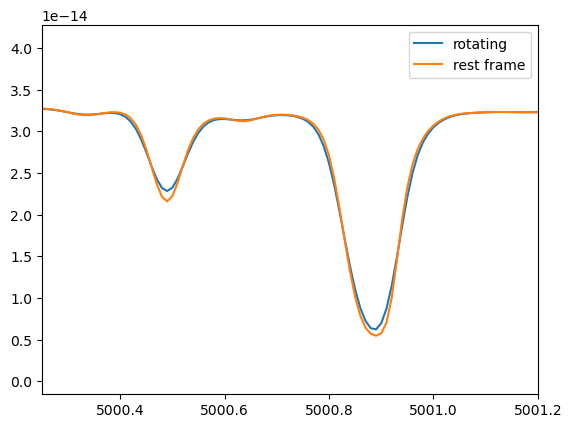

In [9]:
plt.plot(flux_grid_quiet.wv_rot_grid, rot_disk_integrated / ( 1e-8 * flux_grid_quiet.wv_rot_grid**2 * 2.99792458e10)/flux_grid_quiet.total_brightness_rot_grid, label='rotating')
plt.plot(flux_grid_quiet.wv, disk_integrated / ( 1e-8 * flux_grid_quiet.wv**2 * 2.99792458e10)/flux_grid_quiet.total_brightness, label='rest frame')
plt.xlim(5000.25,5001.2)
plt.legend()
plt.show()

In [10]:
##### Masks #####


In [21]:
poet = fits.open('/Users/sophiestucki/Documents/poet/S1D_A/r.ESPRE.2026-05-15T16:07:03.029_S1D_A.fits')

In [32]:
wv_poet = poet[1].data['wavelength']

In [83]:
lamb = wv_poet * u.AA
flux =  poet[1].data['flux'] * u.Unit('erg s-1 cm+2')

spec_poet= Spectrum1D(spectral_axis=lamb, flux=flux) 

lamb_muram = u.Quantity(vacuum2air(flux_grid_quiet.wv_rot_grid), unit=u.AA, copy=False)
flux_muram = u.Quantity(rot_disk_integrated, unit='erg s-1 cm-2 Hz-1', copy=False)

spec_muram = Spectrum1D(spectral_axis=lamb_muram, flux=flux_muram)
fluxcon = FluxConservingResampler()

new_spec_fluxcon = (fluxcon(spec_muram, lamb))



In [84]:
new_spec_fluxcon.data[~np.isnan(new_spec_fluxcon.data)]

array([1.72244021e-06, 1.69709628e-06, 1.66650829e-06, ...,
       6.95020692e-06, 6.95549434e-06, 6.95973462e-06])

In [85]:
flux_grid_quiet.wv_rot_grid

array([3800.034, 3800.04 , 3800.046, ..., 7999.91 , 7999.92 , 7999.93 ])

In [86]:
wv_poet[np.isnan(new_spec_fluxcon.data)]

array([3772.002744  , 3772.00903481, 3772.01532563, ..., 3798.93500862,
       3798.94134435, 3798.94768009], dtype='>f8')

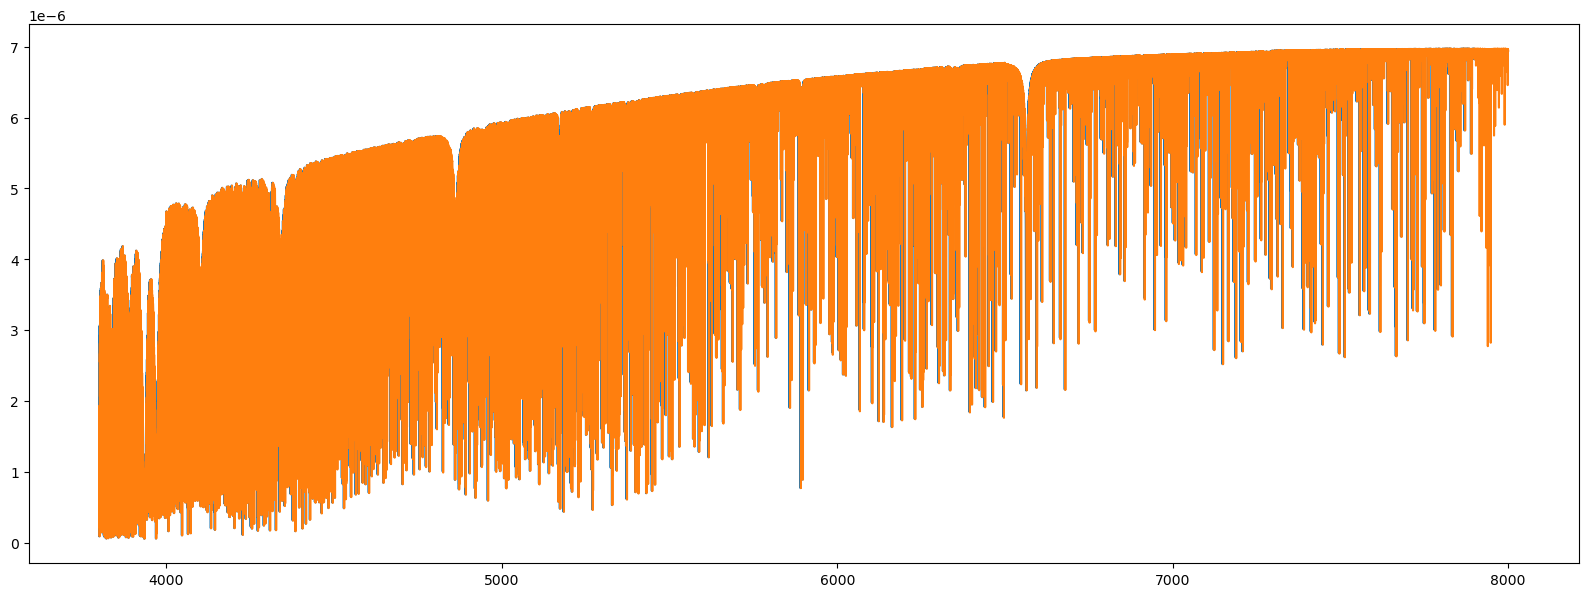

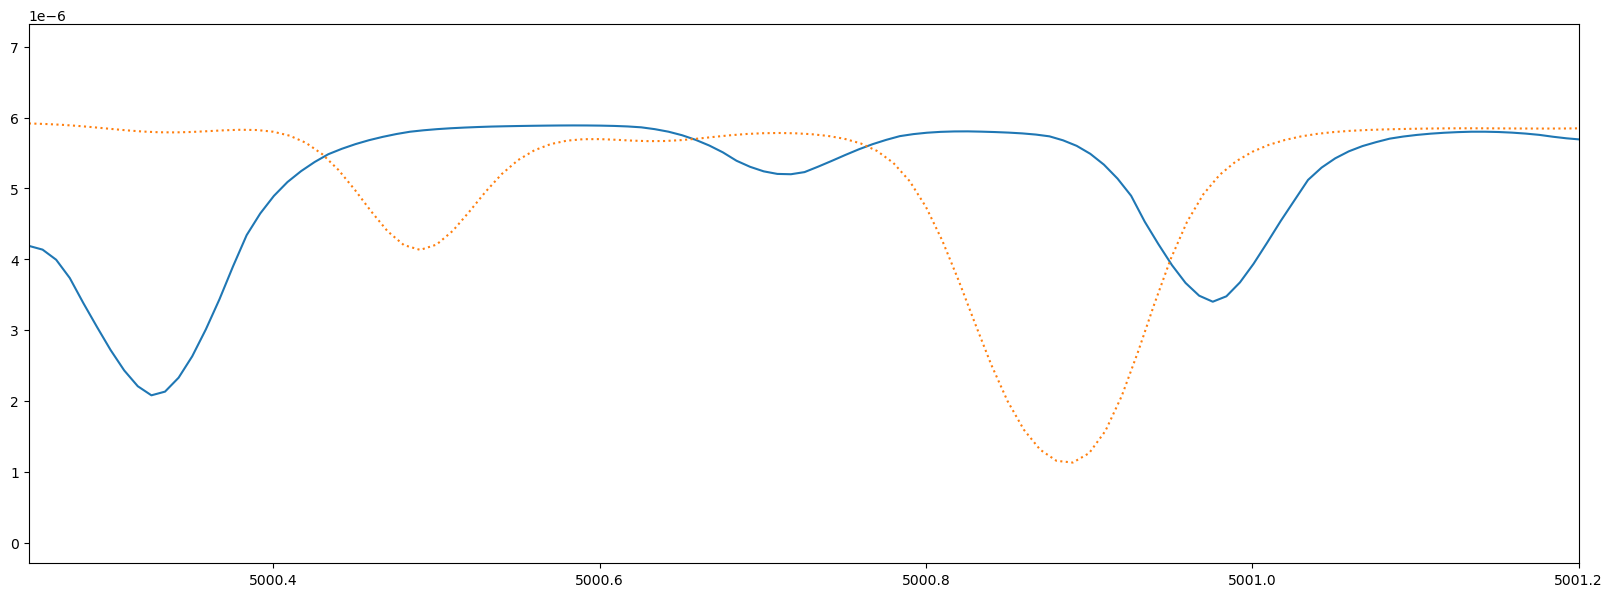

0.024136758536966403 0.024978709285078577


In [87]:
plt.plot(wv_poet,new_spec_fluxcon.data)
plt.plot(flux_grid_quiet.wv_rot_grid, rot_disk_integrated)
plt.show()


plt.plot(wv_poet,new_spec_fluxcon.data)
plt.plot(flux_grid_quiet.wv_rot_grid, rot_disk_integrated, ':')
plt.xlim(5000.25,5001.2)

plt.show()

result1 = integrate.trapezoid(rot_disk_integrated, flux_grid_quiet.wv_rot_grid)
result2 = integrate.trapezoid(wv_poet[~np.isnan(new_spec_fluxcon.data)], new_spec_fluxcon.data[~np.isnan(new_spec_fluxcon.data)])

print(result1, result2)

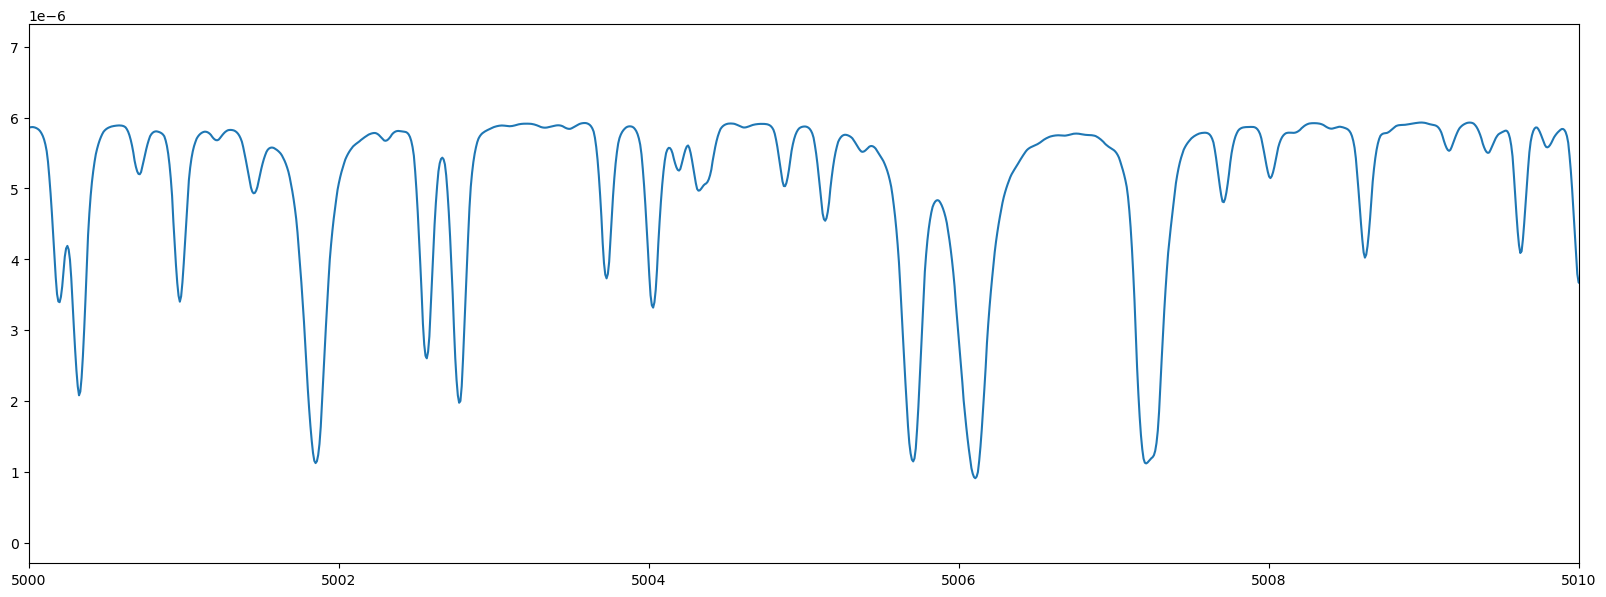

In [88]:
plt.rcParams.update({
        "figure.figsize": (20, 7)})
plt.plot(wv_poet,new_spec_fluxcon.data)
plt.xlim(5000,5010)

plt.show()

In [ ]:
disk_int = {}
disk_int['wav'] = wv_poet[~np.isnan(new_spec_fluxcon.data)]
disk_int['flux'] = new_spec_fluxcon.data[~np.isnan(new_spec_fluxcon.data)]/ ( 1e-8 * wv_poet[~np.isnan(new_spec_fluxcon.data)] **2 * 2.99792458e10) * 1e15
# np.save('/Users/sophiestucki/Documents/poet/disk_integrated_quiet_muram.npy', disk_int, allow_pickle=True)

(5000.0, 5010.0)

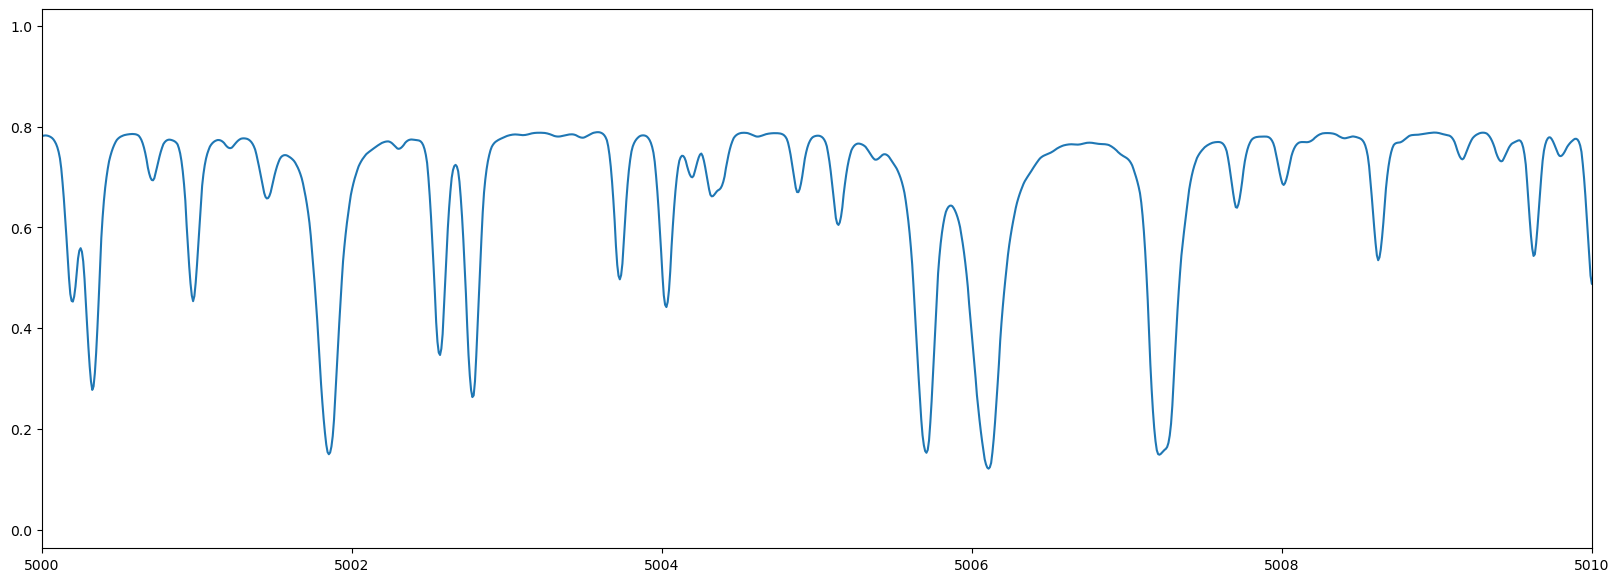

In [95]:
disk_integrated_muram = np.load('/Users/sophiestucki/Documents/poet/disk_integrated_quiet_muram.npy', allow_pickle=True).item()
wv = disk_integrated_muram['wav']
flux = disk_integrated_muram['flux']

plt.plot(wv, flux)
plt.xlim(5000,5010)


In [20]:
##### List #####
spot_1 = active_region('sp', 10, 90, 0)
active_regions_map = [spot_1]

ss = StarSim(time, 10, 0, 25, 0, active_regions_map, flux_grid_quiet.total_brightness, flux_grid_qp=flux_grid_quiet.grid, flux_grid_sp=flux_grid_sp.grid, flux_grid_fc=flux_grid_fc.grid)
ss.generate_rotating_photosphere_lc()

 0.0 0.0
Date 0.0. ff_ph=99.321%. ff_sp=0.679%. ff_fc=0.000%. ff_pl=0.000%. [1/25]%1.0 0.0
Date 1.0416666666666667. ff_ph=100.000%. ff_sp=0.000%. ff_fc=0.000%. ff_pl=0.000%. [2/25]%1.0 0.0
Date 2.0833333333333335. ff_ph=100.000%. ff_sp=0.000%. ff_fc=0.000%. ff_pl=0.000%. [3/25]%1.0 0.0
Date 3.125. ff_ph=100.000%. ff_sp=0.000%. ff_fc=0.000%. ff_pl=0.000%. [4/25]%1.0 0.0
Date 4.166666666666667. ff_ph=100.000%. ff_sp=0.000%. ff_fc=0.000%. ff_pl=0.000%. [5/25]%1.0 0.0
Date 5.208333333333334. ff_ph=100.000%. ff_sp=0.000%. ff_fc=0.000%. ff_pl=0.000%. [6/25]%1.0 0.0
Date 6.25. ff_ph=100.000%. ff_sp=0.000%. ff_fc=0.000%. ff_pl=0.000%. [7/25]%1.0 0.0
Date 7.291666666666667. ff_ph=100.000%. ff_sp=0.000%. ff_fc=0.000%. ff_pl=0.000%. [8/25]%1.0 0.0
Date 8.333333333333334. ff_ph=100.000%. ff_sp=0.000%. ff_fc=0.000%. ff_pl=0.000%. [9/25]%1.0 0.0
Date 9.375. ff_ph=100.000%. ff_sp=0.000%. ff_fc=0.000%. ff_pl=0.000%. [10/25]%1.0 0.0
Date 10.416666666666668. ff_ph=100.000%. ff_sp=0.000%. ff_fc=0.000%. f

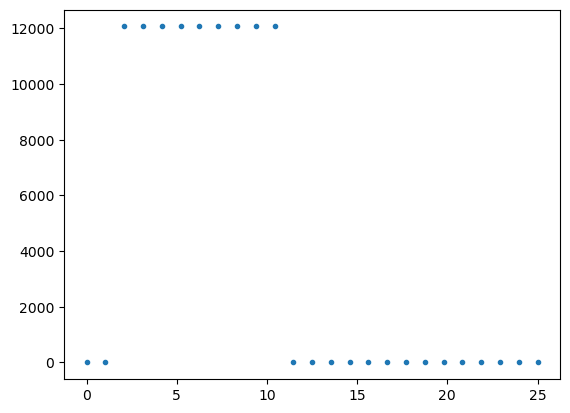

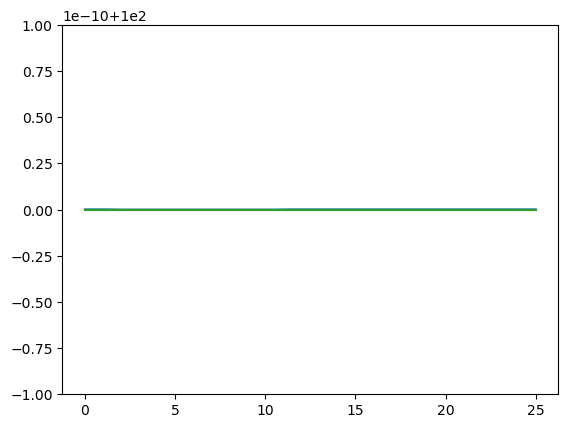

In [12]:
plt.plot(ss.obs_times, np.sum(ss.flux_var, axis=1), '.')
plt.show()
plt.plot(ss.obs_times, ss.ff_quiet)
plt.plot(ss.obs_times, ss.ff_fc+100)
plt.plot(ss.obs_times, ss.ff_sp+100)
plt.show()


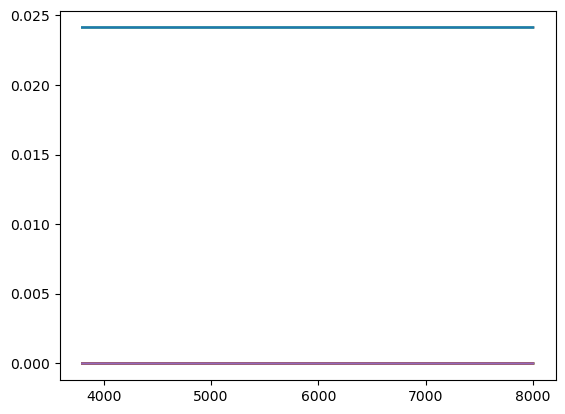

In [14]:
for t in range(len(time)):
    plt.plot(flux_grid_quiet.wv, ss.flux_var[t])
# plt.xlim(5000.7,5001.1)

In [10]:
flux_grid_quiet.vsini

2052.903741094618

In [15]:
##### Computing step-by-step #####
